# Benchmark, baseline y pruebas estadísticas

Las predicciones de 2025 se cargan de `resultados/predicciones_prueba.npz` (generadas por `src/corridas.py`). Aquí
no se entrena nada: solo se evalúa el conjunto de prueba, que estuvo congelado hasta este punto.

In [1]:
import json, sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import bds
sys.path.insert(0, "src")
from datos import cargar

warnings.simplefilter("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
d = cargar()
L, H = d["L"], d["H"]
ix = d["idx"]["prueba"]
y = d["y"][ix + L - 1 + H]                      # velocidad observada en t + 24
pers = d["y"][ix + L - 1]                       # persistencia: v_t
est = d["estacion"]["prueba"]
hora = d["tiempo"][ix + L - 1 + H]
P = np.load("resultados/predicciones_prueba.npz")
corr = pd.DataFrame(json.load(open("resultados/corridas.json")))
MOD = ["MLP", "LSTM", "CNN"]
semillas = sorted({int(k.split("_")[1]) for k in P.files})
print(f"{len(y):,} ventanas de prueba | {len(set(est))} estaciones | {len(semillas)} semillas por modelo")

211,408 ventanas de prueba | 62 estaciones | 6 semillas por modelo


## Tabla comparativa

Cada modelo se entrenó con $R$ semillas. Se reporta la media y la desviación estándar entre semillas de cada
métrica, y el MASE como el cociente entre el MAE del modelo y el de la persistencia a 24 h.

In [2]:
def metricas(p):
    e = p - y
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), R2=1 - np.mean(e ** 2) / np.var(y))

mae_p = np.mean(np.abs(pers - y))
filas = []
for m in MOD:
    met = pd.DataFrame([metricas(P[f"{m}_{s}"]) for s in semillas])
    met["MASE"] = met.MAE / mae_p
    c = corr[corr.modelo == m]
    filas.append({"Modelo": m, **{f"{k} media": met[k].mean() for k in met},
                  "RMSE de": met.RMSE.std(ddof=1), "Parámetros": int(c.parametros.iloc[0]),
                  "Épocas": c.epocas.mean(), "Segundos de entrenamiento": c.segundos.mean()})
filas.append({"Modelo": "Persistencia", **{f"{k} media": v for k, v in metricas(pers).items()}, "MASE media": 1.0,
              "RMSE de": 0.0, "Parámetros": 0, "Épocas": 0, "Segundos de entrenamiento": 0})
tabla = pd.DataFrame(filas).set_index("Modelo")
tabla.round(4)

,RMSE media,MAE media,R2 media,MASE media,RMSE de,Parámetros,Épocas,Segundos de entrenamiento
Modelo,,,,,,,,
MLP,0.7057,0.4979,0.7528,0.8539,0.0024,102785,13.0000,6.4285
LSTM,0.7086,0.4997,0.7507,0.8569,0.0019,13345,12.3333,57.7265
CNN,0.7141,0.5058,0.7468,0.8674,0.0053,44129,14.8333,30.5340
Persistencia,0.8503,0.5831,0.6410,1.0000,0.0000,0,0.0000,0.0000


## Pronóstico promedio por modelo

Para las pruebas por estación y por hora se usa el **promedio de las $R$ semillas** de cada modelo, que es el
pronóstico que se pondría en producción; la variabilidad entre semillas ya quedó en la tabla anterior.

In [3]:
pm = {m: np.mean([P[f"{m}_{s}"] for s in semillas], axis=0) for m in MOD}
pm["Persistencia"] = pers
err2 = pd.DataFrame({m: (p - y) ** 2 for m, p in pm.items()})
err2["estacion"], err2["hora"] = est, hora
rmse_est = err2.groupby("estacion")[list(pm)].mean() ** 0.5
print(f"RMSE por estación ({len(rmse_est)} estaciones), mediana:")
print(rmse_est.median().round(4).to_string())
print("\nRMSE del promedio de semillas:", {m: round(float(np.sqrt(err2[m].mean())), 4) for m in pm})

RMSE por estación (62 estaciones), mediana:


MLP             0.5578
LSTM            0.5601
CNN             0.5755
Persistencia    0.7238

RMSE del promedio de semillas: {'MLP': 0.701, 'LSTM': 0.7022, 'CNN': 0.7065, 'Persistencia': 0.8503}


## Ranking y prueba de Friedman (estaciones como bloques)

La estación es la unidad de independencia declarada a priori, así que cada estación es un bloque y se comparan los
rangos del RMSE de los cuatro pronósticos.

In [4]:
fr = stats.friedmanchisquare(*[rmse_est[m] for m in pm])
rangos = rmse_est.rank(axis=1).mean().sort_values()
print(f"Friedman: chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.2e}")
print("Rango medio (1 = mejor):"); print(rangos.round(2).to_string())

Friedman: chi2 = 107.85, p = 3.19e-23
Rango medio (1 = mejor):
MLP             1.82
LSTM            1.98
CNN             2.24
Persistencia    3.95


### Comparaciones por pares: Wilcoxon con corrección de Holm, diferencia de RMSE y tamaño del efecto

Para cada par se usan las diferencias de RMSE por estación. El tamaño del efecto es la $d$ de Cohen para datos
pareados (media de las diferencias sobre su desviación estándar) y el intervalo de confianza al 95 % de la
diferencia media sale de un bootstrap por estaciones.

In [5]:
pares = [(a, b) for i, a in enumerate(pm) for b in list(pm)[i + 1:]]
rng = np.random.default_rng(0)
filas = []
for a, b in pares:
    dif = (rmse_est[a] - rmse_est[b]).to_numpy()
    boot = [rng.choice(dif, len(dif)).mean() for _ in range(5000)]
    filas.append({"Par": f"{a} − {b}", "ΔRMSE medio": dif.mean(), "IC 95 % inf": np.percentile(boot, 2.5),
                  "IC 95 % sup": np.percentile(boot, 97.5), "d de Cohen": dif.mean() / dif.std(ddof=1),
                  "p Wilcoxon": stats.wilcoxon(dif).pvalue})
wil = pd.DataFrame(filas).set_index("Par")
wil["p Holm"] = multipletests(wil["p Wilcoxon"], method="holm")[1]
wil["Significativo"] = wil["p Holm"] < 0.05
wil.round(4)

,ΔRMSE medio,IC 95 % inf,IC 95 % sup,d de Cohen,p Wilcoxon,p Holm,Significativo
Par,,,,,,,
MLP − LSTM,0.0004,-0.0037,0.0048,0.0245,0.6663,0.6663,False
MLP − CNN,-0.0031,-0.0077,0.0013,-0.1681,0.0476,0.0953,False
MLP − Persistencia,-0.1449,-0.1602,-0.1301,-2.3693,0.0000,0.0000,True
LSTM − CNN,-0.0036,-0.0071,-0.0005,-0.2645,0.0154,0.0463,True
LSTM − Persistencia,-0.1453,-0.1592,-0.1312,-2.5619,0.0000,0.0000,True
CNN − Persistencia,-0.1418,-0.1564,-0.1281,-2.4753,0.0000,0.0000,True


Supuesto de normalidad de las diferencias (relevante para la $d$ de Cohen y la prueba t de la equivalencia):

MLP − LSTM: Shapiro-Wilk p = 0.000
MLP − CNN: Shapiro-Wilk p = 0.000
MLP − Persistencia: Shapiro-Wilk p = 0.049
LSTM − CNN: Shapiro-Wilk p = 0.000
LSTM − Persistencia: Shapiro-Wilk p = 0.102
CNN − Persistencia: Shapiro-Wilk p = 0.212


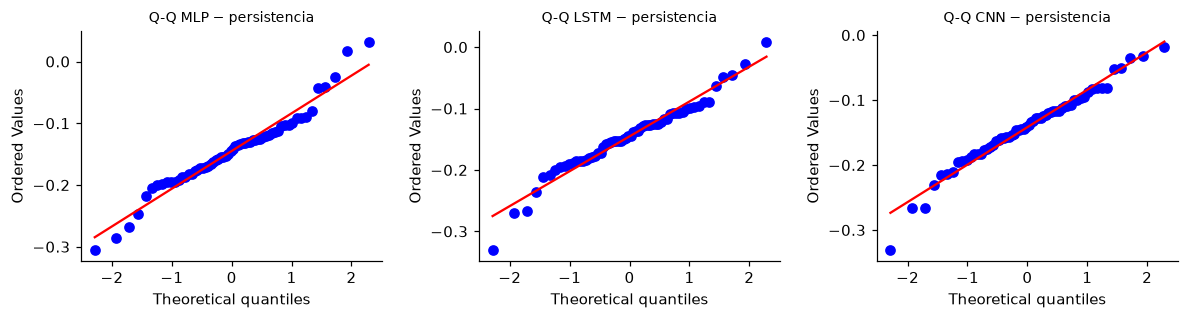

In [6]:
for a, b in pares:
    dif = rmse_est[a] - rmse_est[b]
    print(f"{a} − {b}: Shapiro-Wilk p = {stats.shapiro(dif).pvalue:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a_, (a, b) in zip(ax, [(m, "Persistencia") for m in MOD]):
    stats.probplot(rmse_est[a] - rmse_est[b], plot=a_); a_.set_title(f"Q-Q {a} − persistencia", fontsize=9)
plt.tight_layout(); plt.show()

## Diebold–Mariano con corrección de Harvey–Leybourne–Newbold

La prueba de Diebold–Mariano {cite}`diebold1995` compara la pérdida cuadrática de dos pronósticos hora a hora.
Se promedia el diferencial de pérdida entre las estaciones activas en cada hora, para obtener una sola serie
temporal, y se usa la varianza de largo plazo con $h - 1 = 23$ rezagos (el pronóstico es a 24 h, así que los errores
consecutivos se solapan) y la corrección para muestras finitas de {cite}`harvey1997`.

In [7]:
def dm_hln(dl, h=24):
    dl = np.asarray(dl); T = len(dl); dbar = dl.mean(); u = dl - dbar
    gam = [u @ u / T] + [u[k:] @ u[:-k] / T for k in range(1, h)]
    v = (gam[0] + 2 * sum(gam[1:])) / T
    dm = dbar / np.sqrt(v)
    hln = dm * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return hln, 2 * stats.t.sf(abs(hln), df=T - 1)

filas = []
for a, b in pares:
    serie = (err2[a] - err2[b]).groupby(err2.hora).mean().sort_index()
    est_, p = dm_hln(serie)
    filas.append({"Par": f"{a} − {b}", "Diferencial medio": serie.mean(), "DM-HLN": est_, "p": p})
dm = pd.DataFrame(filas).set_index("Par")
dm["p Holm"] = multipletests(dm.p, method="holm")[1]
dm.round(4)

,Diferencial medio,DM-HLN,p,p Holm
Par,,,,
MLP − LSTM,0.0019,0.4418,0.6586,0.6586
MLP − CNN,-0.0049,-1.2994,0.1939,0.3877
MLP − Persistencia,-0.2357,-19.8874,0.0000,0.0000
LSTM − CNN,-0.0068,-3.3698,0.0008,0.0023
LSTM − Persistencia,-0.2376,-22.4369,0.0000,0.0000
CNN − Persistencia,-0.2308,-20.6239,0.0000,0.0000


Un diferencial negativo indica que el primer modelo del par tiene menor error cuadrático.

## Equivalencia práctica (TOST) entre los dos mejores modelos

Que una diferencia no sea significativa no prueba que los modelos sean iguales. La prueba TOST contrasta si la
diferencia media de RMSE por estación cae dentro del margen declarado a priori, $\pm\delta = \pm 0.02$ m/s.

In [8]:
delta = 0.02
mejores = [m for m in rangos.index if m != "Persistencia"][:2]
dif = (rmse_est[mejores[0]] - rmse_est[mejores[1]]).to_numpy()
p_inf = stats.ttest_1samp(dif, -delta, alternative="greater").pvalue
p_sup = stats.ttest_1samp(dif, delta, alternative="less").pvalue
print(f"{mejores[0]} − {mejores[1]}: diferencia media {dif.mean():.4f} m/s | TOST p = {max(p_inf, p_sup):.4f}")
print("Equivalentes dentro de ±δ" if max(p_inf, p_sup) < 0.05 else "No se puede afirmar equivalencia dentro de ±δ")

MLP − LSTM: diferencia media 0.0004 m/s | TOST p = 0.0000
Equivalentes dentro de ±δ


## Diagnóstico de los residuos del mejor modelo

Si el pronóstico aprovechara toda la información, los residuos no tendrían estructura. Se aplican Ljung-Box
(autocorrelación) y BDS (dependencia no lineal) a los residuos de cada estación con un tramo continuo suficiente.

In [9]:
mejor = mejores[0]
res_ = pd.DataFrame({"r": pm[mejor] - y, "estacion": est, "hora": hora})
filas = []
for c, g in res_.groupby("estacion"):
    s = g.set_index("hora").r.sort_index().asfreq("h").dropna()
    if len(s) < 1000:
        continue
    lb = acorr_ljungbox(s, lags=[24], return_df=True).lb_pvalue.iloc[0]
    b = bds(s.iloc[:3000].to_numpy(), max_dim=2)[1]
    filas.append((c, lb, float(np.atleast_1d(b)[0])))
diag = pd.DataFrame(filas, columns=["estacion", "p_LjungBox_24", "p_BDS_m2"])
print(f"{len(diag)} estaciones | Ljung-Box p < 0.05: {(diag.p_LjungBox_24 < .05).sum()} | "
      f"BDS p < 0.05: {(diag.p_BDS_m2 < .05).sum()}")
print(f"Sesgo medio de los residuos de {mejor}: {res_.r.mean():.3f} m/s")

53 estaciones | Ljung-Box p < 0.05: 53 | BDS p < 0.05: 53
Sesgo medio de los residuos de MLP: -0.011 m/s


## Error por mes y por nivel de viento

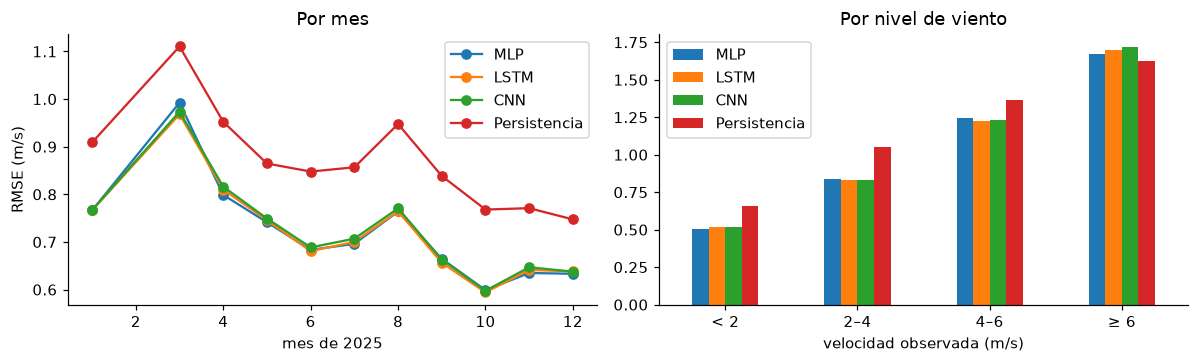

Sesgo por nivel (predicho − observado):
       MLP   LSTM    CNN  Persistencia
< 2  0.194  0.212  0.214         0.151
2–4 -0.319 -0.297 -0.288        -0.245
4–6 -0.746 -0.715 -0.744        -0.476
≥ 6 -1.225 -1.271 -1.274        -0.768


In [10]:
mes = pd.DatetimeIndex(hora).month
por_mes = err2.groupby(mes)[list(pm)].mean() ** 0.5
nivel = pd.cut(y, [0, 2, 4, 6, 30], right=False, labels=["< 2", "2–4", "4–6", "≥ 6"])
por_nivel = err2.groupby(nivel, observed=True)[list(pm)].mean() ** 0.5
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
por_mes.plot(ax=ax[0], marker="o"); ax[0].set(xlabel="mes de 2025", ylabel="RMSE (m/s)", title="Por mes")
por_nivel.plot.bar(ax=ax[1], rot=0); ax[1].set(xlabel="velocidad observada (m/s)", title="Por nivel de viento")
plt.tight_layout(); plt.show()
print("Sesgo por nivel (predicho − observado):")
print(pd.DataFrame({m: (pm[m] - y) for m in pm}).groupby(nivel, observed=True).mean().round(3).to_string())